# Vektorske reprezentacije rečenica za grupisanje dokumenata (vesti)

Ovaj notebook prikazuje primer grupisanja tekstualnih podataka (clustering) koriscenjem:

* **SentenceTransformers** – Python biblioteke za kreiranje vektorskih reprezentacija recenica i tekstova.
* **Pretreniranog modela za kreiranje vektorskih reprezentacija (sentence embeddings)**, koji je dostupan na [HuggingFace](https://huggingface.co/models) platformi.
* **Hijerarhijskog algoritma grupisanja (Hierarchical Clustering)** – algoritma koji grupise dokumente na osnovu njihove medjusobne slicnosti.

Na kraju, prikazana je i upotreba **TF-IDF vektorizatora** za izdvajanje najznacajnijih grupa reci (n-grama) u okviru svakog klastera, kako bi se lakse razumelo o kojim temama govore dokumenti koji pripadaju odredjenom klasteru.

Podaci korisceni u ovom primeru preuzeti su sa Kaggle platforme, iz skupa podataka [BBC News](https://www.kaggle.com/datasets/gpreda/bbc-news), koji sadrzi novinske članke.

In [ ]:
# !pip -q install sentence-transformers
# !pip -q install pypalettes

In [1]:
# !!! SVI IMPORTI CE BITI DATI NA KOLOKVIJUMU

import pandas as pd
import numpy as np
from IPython.core.pylabtools import figsize
from pandas.core.common import random_state

# moduli za klasterovanje
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import silhouette_score
import scipy.cluster.hierarchy as shc

# moduli za vizuelizaciju
import matplotlib.pyplot as plt
import seaborn as sb
from pypalettes import load_cmap

from pathlib import Path
from dotenv import load_dotenv
import os

from cas import ward_linkage

In [2]:
RAND_STATE = 1

# Pretrenirani model za kreiranje vektorskih reprezentacija recenica
PRETRAINED_LM = "all-MiniLM-L12-v2"

Pretrenirani model `all-MiniLM-L12-v2` pretvara tekstove u numericke vektore (embeddings) od 384 dimenzije. Vektori cuvaju semanticko znacenje tekstova i koriste se za poredjenje slicnosti i grupisanje vesti. Model podrzava ulaz do 256 tokena.

Podsetimo se da smo imali i model `en_core_web_md`. Oba modela sluze za pretvaranje tekstualnih podataka u numericke vektorske reprezentacije (embeddings). Razlika je u tome sto `all-MiniLM-L12-v2` generise vektor za celu recenicu ili dokument, dok `en_core_web_md` prvenstveno poseduje vektorske reprezentacije pojedinacnih reci, na osnovu kojih moze da formira i vektorsku reprezentaciju celog dokumenta.

In [3]:
# ova klasa se koristi za ucitavanje pretreniranih modela koji pretvaraju recenice i tekstualne dokumente u vektorske reprezentacije (embeddings)

from sentence_transformers import SentenceTransformer

C:\Users\User\AppData\Local\Programs\Python\Python313\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## UCITAVANJE I PREGLED PODATAKA

In [4]:
data = pd.read_csv(Path.cwd() / 'data' / 'bbc_news.csv')

data.head()

,title,pubDate,guid,link,description
0,Ukraine: Angry Zelensky vows to punish Russian...,"Mon, 07 Mar 2022 08:01:56 GMT",https://www.bbc.co.uk/news/world-europe-60638042,https://www.bbc.co.uk/news/world-europe-606380...,The Ukrainian president says the country will ...
1,War in Ukraine: Taking cover in a town under a...,"Sun, 06 Mar 2022 22:49:58 GMT",https://www.bbc.co.uk/news/world-europe-60641873,https://www.bbc.co.uk/news/world-europe-606418...,"Jeremy Bowen was on the frontline in Irpin, as..."
2,Ukraine war 'catastrophic for global food',"Mon, 07 Mar 2022 00:14:42 GMT",https://www.bbc.co.uk/news/business-60623941,https://www.bbc.co.uk/news/business-60623941?a...,One of the world's biggest fertiliser firms sa...
3,Manchester Arena bombing: Saffie Roussos's par...,"Mon, 07 Mar 2022 00:05:40 GMT",https://www.bbc.co.uk/news/uk-60579079,https://www.bbc.co.uk/news/uk-60579079?at_medi...,The parents of the Manchester Arena bombing's ...
4,Ukraine conflict: Oil price soars to highest l...,"Mon, 07 Mar 2022 08:15:53 GMT",https://www.bbc.co.uk/news/business-60642786,https://www.bbc.co.uk/news/business-60642786?a...,Consumers are feeling the impact of higher ene...


In [5]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 42115 entries, 0 to 42114
Data columns (total 5 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   title        42115 non-null  object
 1   pubDate      42115 non-null  object
 2   guid         42115 non-null  object
 3   link         42115 non-null  object
 4   description  42115 non-null  object
dtypes: object(5)
memory usage: 1.6+ MB


In [6]:
data.duplicated().sum()

np.int64(0)

In [7]:
# s obzirom da je dataset prevelik (preko 42 hiljade podataka), ceo proces klasterizacije bi mogao da bude previse spor - analiziracemo samo vesti iz jedne godine

try:
    data['pub_date'] = pd.to_datetime(data.pubDate, format="%a, %d %b %Y %H:%M:%S GMT", errors='raise')
except ValueError as err:
    print(err)

In [8]:
data['pub_year'] = data.pub_date.dt.year
data.pub_year.value_counts()

# klasterizovacemo vesti iz 2024. godine jer su "najsvezije", ali s obzirom da je broj vesti i dalje veliki uzecemo random samle od 4000

pub_year
2023    15043
2024    14761
2022    12301
2021        6
2019        1
2017        1
2013        1
2018        1
Name: count, dtype: int64

In [9]:
data2024 = data.loc[data.pub_year == 2024].sample(n=4000, random_state=RAND_STATE).copy()

# uklanjanje kolona koje nisu potrebne
data2024.drop(columns=['pubDate', 'pub_date'], inplace=True)

# resetovanje indeksa jer smo uzeli random uzorak
data2024.reset_index(drop=True, inplace=True)

data2024.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4000 entries, 0 to 3999
Data columns (total 5 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   title        4000 non-null   object
 1   guid         4000 non-null   object
 2   link         4000 non-null   object
 3   description  4000 non-null   object
 4   pub_year     4000 non-null   int32 
dtypes: int32(1), object(4)
memory usage: 140.8+ KB


Spajamo kolone `title` (naslov) i `description` (opis) kako bismo dobili jedinstven tekstualni sadrzaj svake vesti. Tako dobijen tekst koristimo u daljoj obradi vesti i njihovom grupisanju (clustering).

In [10]:
data2024['content'] = data2024.apply(lambda x: f"{x['title']}. {x['description']}", axis=1)
# axis=1 - funkcija se primenjuje po redovima (za svaku vest posebno), default je 0

data2024[['title', 'description', 'content']].head()

,title,description,content
0,Train strikes: What routes are affected when?,"Train drivers have been staging strikes, coinc...",Train strikes: What routes are affected when?....
1,'I'm not Harry Potter' - Ten Hag defends Man U...,Manchester United manager Erik ten Hag says he...,'I'm not Harry Potter' - Ten Hag defends Man U...
2,Thousands more appointments hit by doctor strike,"The NHS England said 91,000 appointments and p...",Thousands more appointments hit by doctor stri...
3,"Labour manifesto all about wealth creation, sa...","Sir Keir Starmer says there will be ""no surpri...","Labour manifesto all about wealth creation, sa..."
4,In defence of Foden - 'this is a tactical issu...,BBC pundit Micah Richards argues Phil Foden's ...,In defence of Foden - 'this is a tactical issu...


Proveravamo broj reci u svakom tekstu kako bismo utvrdili da li tekstovi prekoracuju ogranicenje modela od 256 tokena. Ako je potrebno, tekstove skracujemo na oko 200 reci.

In [11]:
data2024['word_count'] = data2024.content.apply(lambda x: len(x.split()))
data2024.word_count.describe()

count    4000.000000
mean       26.443750
std         4.854454
min         5.000000
25%        23.000000
50%        26.000000
75%        29.000000
max        51.000000
Name: word_count, dtype: float64

**SBERT** (Sentence-BERT) je model zasnovan na BERT arhitekturi, namenjen kreiranju vektorskih reprezentacija celih recenica i dokumenata. Koristimo pretrenirani model `all-MiniLM-L12-v2` za pretvaranje vesti u embeddings, koji se kasnije koriste za poredjenje slicnosti i grupisanje tekstova.

Model podrzava ulaz do 256 tokena, sto okvirno odgovara 170–200 reci na engleskom jeziku. Za razdvajanje teksta na tokene koristi se WordPiece tokenizer, koji pojedine duze ili redje reci moze podeliti na vise manjih delova.

**Napomena**: en_core_web_md je pretrenirani engleski jezik model iz biblioteke spaCy

## PRISTUM **HUGGINGFACE** MODELIMA

HuggingFace je platforma koja omogucava pronalazenje i preuzimanje pretreniranih modela. U ovom primeru sa nje preuzimamo SBERT model `all-MiniLM-L12-v2`, koji koristimo za kreiranje vektorskih reprezentacija tekstova vesti.

**Napomena:** Za pristup modelima sa HuggingFace repozitorijuma potrebno je imati HuggingFace nalog i pristupni token (Access Token).

Token se generise nakon prijavljivanja na platformu, u okviru opcije Settings → Access Tokens → New Token. Prilikom kreiranja tokena potrebno je odabrati odgovarajucu ulogu (Role).

Ako se notebook pokrece lokalno, token se moze sacuvati u `.env` fajlu, u obliku `HF_TOKEN=token_value`, a zatim ucitati u Python kodu.

**Poenta:** Pristupni token sluzi za autentifikaciju prilikom pristupa HuggingFace platformi i njenim modelima. Nije potrebno direktno upisivati token u kod, vec ga je bolje cuvati u posebnom, bezbednom okruzenju.

In [12]:
load_dotenv()  # ucitavamo promenljive iz .env

# os.getenv - uzima vrednost pojedinacne promenljive
if os.getenv('HF_TOKEN'):
    print('USPESNO ucitan HF token')
else:
    print('GRESKA pri ucitavanju HF tokena')

USPESNO ucitan HF token


In [13]:
model = SentenceTransformer(PRETRAINED_LM)

Loading weights: 100%|██████████| 199/199 [00:00<00:00, 1778.44it/s]


# KLASTEROVANJE

Da bismo grupisali dokumente (vesti), potrebno je da procenimo koliko su oni medjusobno slicni.

Postupak se sastoji iz dva koraka:

1. **Transformacija dokumenata u vektore (embeddings)** – svaka vest se predstavlja numerickim vektorom. Na primer, model `all-MiniLM-L12-v2` kreira vektore od 384 dimenzije.
2. **Racunanje kosinusne slicnosti (cosine similarity)** – uporedjujemo vektore kako bismo utvrdili koliko su njihove vektorske reprezentacije slicne.

### Cosine Similarity

Kosinusna slicnost meri slicnost dva vektora na osnovu ugla izmedju njih.

- Vrednost blizu `1` – vektori su veoma slicni.
- Vrednost blizu `0` – vektori su slabo slicni ili nepovezani.
- Vrednost blizu `-1` – vektori su suprotno usmereni.

**Vazno:** Cosine similarity sama po sebi ne vrsi grupisanje, vec samo meri slicnost izmedju vektora. Algoritam za klasterovanje, kao sto je K-Means, koristi vektorske reprezentacije za rasporedjivanje dokumenata u grupe.

**Postupak:**

`Tekst → Embeddings → Racunanje slicnosti → Clustering`

#### 1. EMBEDDINGS

In [14]:
news_embeddings = model.encode(data2024.content.to_numpy())

# model.encode() pretvara tekstove vesti u numericke vektorske reprezentacije (embeddings)
# .to_numpy() pretvara pandas Series u NumPy niz (np.ndarray), koji metoda encode() ocekuje kao ulaz

news_embeddings.shape
# svaki tekst opisan vektorom od 384 dimenzije

(4000, 384)

In [15]:
news_embeddings[:5, ]

array([[ 0.04113671, -0.02983462, -0.00551188, ...,  0.0074884 ,
         0.00931509,  0.03954294],
       [-0.08120069,  0.06985077,  0.00346195, ..., -0.00491068,
        -0.04686562, -0.02456838],
       [-0.03069473, -0.00363694, -0.01168081, ..., -0.00084324,
         0.01408124,  0.0580618 ],
       [-0.02642021,  0.07772511,  0.04414241, ..., -0.01286609,
         0.11840671,  0.00778101],
       [ 0.01402359,  0.07168365, -0.06727007, ..., -0.00772562,
         0.04792239,  0.08223984]], shape=(5, 384), dtype=float32)

#### 2. KOSINUSNA SLICNOST

In [16]:
news_similarities = cosine_similarity(news_embeddings, news_embeddings)
news_similarities.shape

# prosledjivanjem news_embeddings dva puta racuna se slicnost svake vesti sa svakom drugom vescu, ukljucujuci i samu sebe
# news_similarities – matrica slicnosti u kojoj svaki element predstavlja slicnost izmedju dva dokumenta

(4000, 4000)

In [17]:
# PRIMER
sample_news_item = data2024.content.sample(random_state=RAND_STATE)

sample_index = sample_news_item.index[0]
sample = sample_news_item.iloc[0]

print(sample)
print(sample_index)

Burrow was sporting great and inspiring MND campaigner. A champion on and off the field, Rob Burrow's determination, courage and humility ensures a legacy that stretches way beyond rugby league.
200


In [18]:
n_news = news_similarities.shape[0]
news_scores = [{'index': i, 'score': news_similarities[sample_index, i]} for i in range(n_news) if i != sample_index]

sorted_news_scores = sorted(news_scores, key=lambda news: news['score'], reverse=True)

print('Pet najslicnijih vesti:\n')
for news in sorted_news_scores[:5]:
    similar_news = data2024.content.iloc[news['index']]
    print(f"VEST: {similar_news}\nSlicnost: {news['score']:.4f}\n")

Pet najslicnijih vesti:

VEST: Rugby League legend Rob Burrow dies aged 41. The Leeds Rhinos star was diagnosed with motor neurone disease two years after he retired from playing, following a stellar 17-year career.
Slicnost: 0.7049

VEST: A giant and an 'absolute legend' - remembering Rob Burrow. BBC Sport looks back at Rob Burrow's greatest achievements, featuring tributes from his family and friends, after the rugby league legend and motor neurone disease campaigner died aged 41.
Slicnost: 0.6770

VEST: 'Hero Rob's final message' and Farage returns. Nigel Farage's return and Rob Burrow's inspiring final voice note lead Tuesday's papers.
Slicnost: 0.3833

VEST: Garth Crooks' Team of the Week: Saka, Haaland, Rice, Gallagher. Which players impressed our football pundit Garth Crooks enough to make his latest Team of the Week?
Slicnost: 0.3625

VEST: Home damage victim shocked by rugby captain choice. A year before naming Cory Hill captain, Wales coach met victim of house attack involvin

### 3. Agglomerative Hierarchical Clustering (Hijerarhijsko grupisanje)

Za grupisanje vesti na osnovu njihove slicnosti (cosine similarity) koristimo **agglomerative hierarchical clustering**.

----------

#### Racunanje kosinusne udaljenosti (Cosine Distance)

Posto smo vec izracunali kosinusnu slicnost izmedju vesti (`news_similarities`), mozemo je iskoristiti za hijerarhijsko klasterovanje.

Medjutim, linkage metode rade sa **udaljenostima (distances)**, a ne sa slicnostima (similarities). Zato je potrebno da kosinusnu slicnost pretvorimo u kosinusnu udaljenost.

Formula:

`cosine_distance = 1 - cosine_similarity`

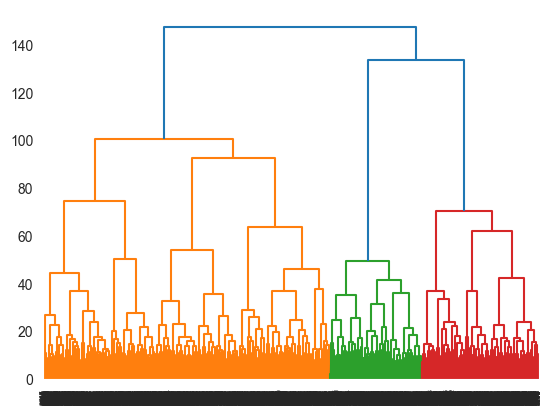

In [19]:
news_dist = 1 - news_similarities

ward_linkage = shc.linkage(news_dist, method='ward')

plt.figure()
shc.dendrogram(ward_linkage)
plt.show()

## Odredjivanje optimalnog broja klastera

Dendrogram sugerise da bi broj klastera izmedju 3 i 6 mogao biti odgovarajuci izbor.

Medjutim, dendrogram ne daje jednoznacan odgovor o optimalnom broju klastera, pa je potrebno koristiti dodatne metrike (pokazatelje) kako bismo doneli odluku.

Na osnovu tih pokazatelja mozemo proceniti koji broj klastera daje najbolje rezultate grupisanja.

--------------------

## Silhouette Score – Poredjenje klasterovanja

Postoji vise metrika za procenu kvaliteta klasterovanja i poredjenje razlicitih resenja. Jedna od najcesce koriscenih je **Silhouette Score**, koja pokazuje koliko je neka tacka slicna svom klasteru u odnosu na susedne klastere.

Silhouette Score se zasniva na dve mere:

### 1. Cohesion – Unutarklasterska udaljenost

Oznacava prosecnu udaljenost tacke `i` od svih ostalih tacaka koje pripadaju istom klasteru. Manja vrednost znaci da je tacka bliza ostalim tackama svog klastera. Pozeljno je da ova vrednost bude sto manja.

### 2. Separation – Udaljenost do najblizeg susednog klastera

Oznacava prosecnu udaljenost tacke `i` od svih tacaka u najblizem susednom klasteru, odnosno najblizem klasteru kojem ta tacka ne pripada. Veca vrednost znaci da je tacka udaljenija od drugih klastera. Pozeljno je da ova vrednost bude sto veca.

### Tumacenje rezultata

Silhouette Score ima vrednost u opsegu od `-1` do `1`:

- **Blizu 1** – tacka je dobro uklopljena u svoj klaster i udaljena od susednih klastera.
- **Blizu 0** – tacka se nalazi blizu granice izmedju dva klastera.
- **Blizu -1** – tacka je verovatno pogresno rasporedjena i bliza je nekom drugom klasteru.

**Cilj je da Silhouette Score bude sto veci.**

### Izbor optimalnog broja klastera

Da bismo odredili optimalan broj klastera:

1. Formiramo klastere za razlicite vrednosti broja klastera (`3`, `4`, `5` i `6`).
2. Za svako resenje racunamo prosecni Silhouette Score.
3. Uporedjujemo dobijene rezultate.
4. Biramo broj klastera koji ostvaruje najvisi Silhouette Score.

Dakle, **resenje sa najvisim Silhouette Score-om smatra se najboljim prema ovoj metrici.**

In [20]:
silhouette_scores = []

for k in range(3, 7):
    # fcluster odredjuje pripadnost svakog dokumenta klasteru za zadati broj klastera
    agg_clust = shc.fcluster(ward_linkage, t=k, criterion='maxclust')

    # uklanja veoma male negativne vrednosti iz matrice udaljenosti
    news_dist_clipped = np.clip(news_dist, a_min=0.0, a_max=None)

    # Racuna prosecni Silhouette Score za dobijeno klasterovanje
    sil_score = silhouette_score(news_dist_clipped, agg_clust, metric='precomputed')
    # metric='precomputed' – oznacava da se prosledjuje vec izracunata matrica udaljenosti, a ne originalni vektori

    # dodaje rezultat u listu
    silhouette_scores.append(sil_score)

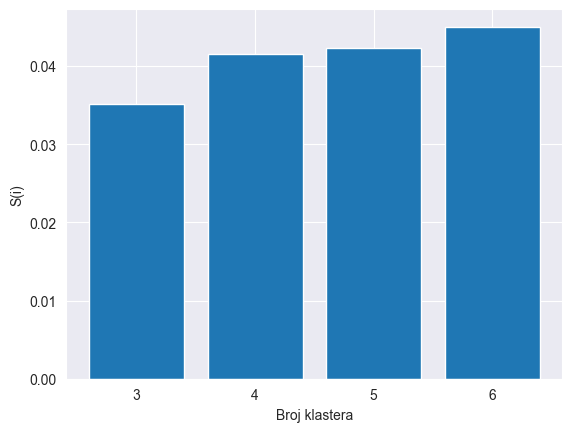

In [21]:
plt.bar(range(3, 7), silhouette_scores)
plt.xlabel('Broj klastera')
plt.ylabel('S(i)')
plt.xticks(range(3, 7))
plt.show()

Na osnovu Silhouette score-a i dendrograma, izabrano je resenje sa **6 klastera**.

Prosecna vrednost Silhouette score-a je veoma niska, sto ukazuje na to da klasteri nisu jasno razdvojeni. To je ocekivano kod grupisanja novinskih clanaka, jer razlicite vesti mogu obradjivati slicne teme, pa granice izmedju klastera nisu uvek jasne.

Sledeci korak je da proverimo **velicinu i uravnotezenost klastera**, odnosno koliko clanaka pripada svakom od sest klastera.

In [22]:
agg_clust_opt = shc.fcluster(ward_linkage, t=6, criterion='maxclust')
pd.Series(agg_clust_opt).value_counts()

# Raspodela clanaka po klasterima nije idealno uravnotezena, jer klasteri nemaju priblizno isti broj elemenata.
# Ipak, na osnovu dendrograma, ovakva neravnomerna raspodela bi postojala bez obzira na to koji smislen broj klastera izaberemo.

6    942
5    740
4    733
3    675
1    549
2    361
Name: count, dtype: int64

### Korak 4: Karakterisanje klastera na osnovu kljucnih reci

Da bismo stekli predstavu o tome kojom temom se bavi svaki klaster, izdvojicemo najrelevantnije n-grame na osnovu TF-IDF vrednosti.

Na osnovu najznacajnijih n-grama opisacemo i karakterisati svaki klaster.

In [23]:
data2024['cluster'] = agg_clust_opt


def get_top_ngrmas(cluster_id, top_n=10, words_to_remove=None):
    tfidf_vectorizer = TfidfVectorizer(
        stop_words='english',
        # inace smo koristili spacy, ali da ne bismo gubili vreme... npr klaster 2 bez lemantizacije ima i year i years
        ngram_range=(1, 2)
    )

    # za izabrani klaster izvlacimo content za svaku vest tog klastera
    cluster_news = data2024.loc[data2024.cluster == cluster_id].content
    # racunanje tf-idf vrednosti za izabrane vesti
    cluster_tfidf = tfidf_vectorizer.fit_transform(cluster_news)
    # vraca listu svih n-grama koji su se pojavili u tekstovima
    candidate_keywords = tfidf_vectorizer.get_feature_names_out()

    # racunamo prosecnu TF-IDF vrednost svakog n-grama kroz sve clanke u klasteru
    mean_tfidf = np.asarray(cluster_tfidf.mean(axis=0)).flatten()

    # kreiramo uredjeni par (ngram, tf-idf score) i sortiramo u opadajucem redosledu tf-idf score-a
    sorted_candidates = sorted([(keyword, tfidf_score) for keyword, tfidf_score in zip(candidate_keywords, mean_tfidf)],
                               key=lambda item: item[1], reverse=True)

    if words_to_remove:
        sorted_candidates = [(keyword, score) for keyword, score in sorted_candidates if keyword not in words_to_remove]

    return sorted_candidates[:top_n]

In [24]:
# PRIMER
get_top_ngrmas(cluster_id=2)

[('rates', np.float64(0.01172224070258919)),
 ('new', np.float64(0.011372034977549579)),
 ('world', np.float64(0.010485059035999132)),
 ('mortgage', np.float64(0.009634028939669043)),
 ('says', np.float64(0.00861676890913804)),
 ('people', np.float64(0.00831789289044341)),
 ('energy', np.float64(0.008247840866068366)),
 ('prices', np.float64(0.008241255614962875)),
 ('bills', np.float64(0.008078291854724494)),
 ('years', np.float64(0.00786247130511439))]

#### PRIKAZ KLUCNIH RECI

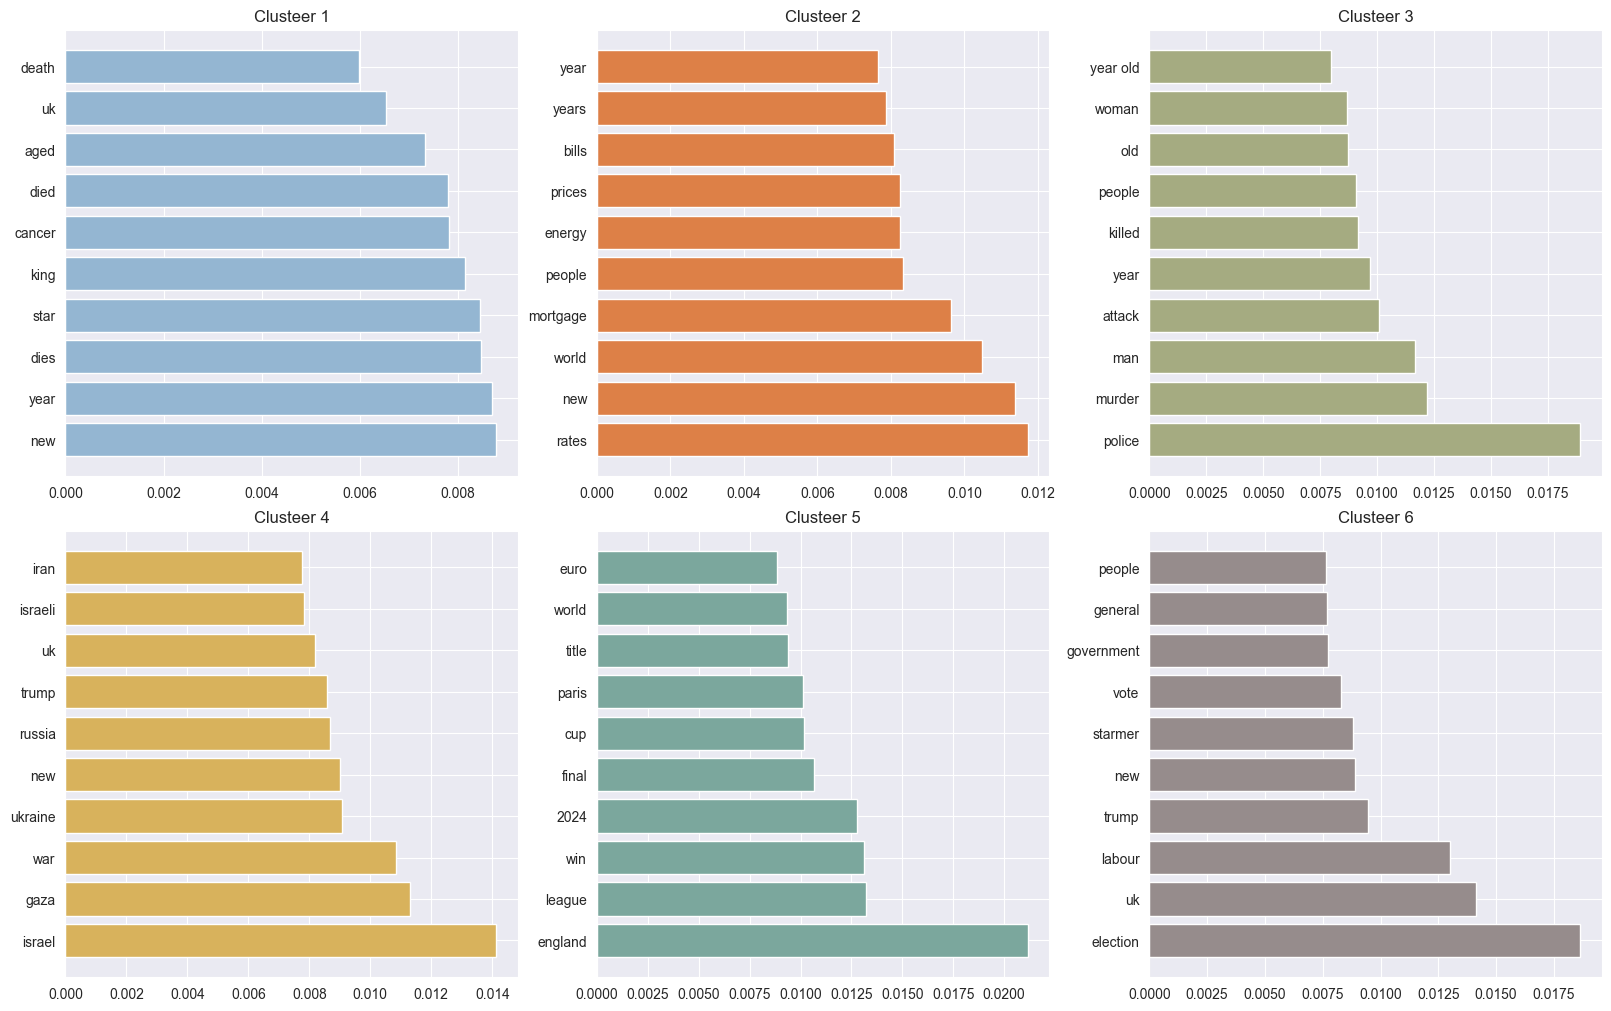

In [58]:
# !!! KODOVI ZA VIZUELIZACIJU CE BITI DATI NA KOLOKVIJUMU

fix, ax_grid = plt.subplots(nrows=2, ncols=3, figsize=(16,10), constrained_layout=True)

axes = ax_grid.flatten()

cmap = load_cmap("excel_Median")

n_clust = data2024.cluster.nunique()
for i in range(n_clust):
    data = get_top_ngrmas(i+1, words_to_remove=['bbc','says'])
    #data = sorted(data, key=lambda item:item[1])
    scores = [s for kw,s in data]
    keywords = [kw for kw,s in data]

    axes[i].barh(keywords, scores, color=cmap(i))
    axes[i].set_title(f"Clusteer {i+1}")

plt.show()

Na osnovu kljucnih reci mozemo otprilike da utvrdimo o cemu je rec:

1 - ?

2 - ekonomija

3 - kriminalistika

4 - ratovi

5 - sport

6 - politika

In [ ]:
# posto za klaster 1 ne moze da utvrdimo na osnovu kljucnih reci mozemo da probamo preko naslova

data2024.loc[data2024.cluster==1,'title'].sample(10)

# sad mozemo da kazemo da je u pitanju neka estrada

# s obzirom da je ovaj klaster ovakav mozda je moglo da se radi i sa 5 klastera